# Touch, force and sound

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/4_data_and_hardware/05_touch_force_and_sound.ipynb) &nbsp; Guide note: [guide-senses](https://www.matthewwnuk.com/guide-senses.html)

Cameras lead until the hand closes. After that, force, touch and sound carry the information. This
notebook looks at real recordings of each, builds a spectrogram from scratch, and turns one second of
sound into the tokens a transformer would receive.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()

## One press, three sensors

A fingertip presses on an object. A camera inside the soft fingertip images its skin, a 12 x 12 array
measures pressure, and a sensor at the wrist measures the total force.

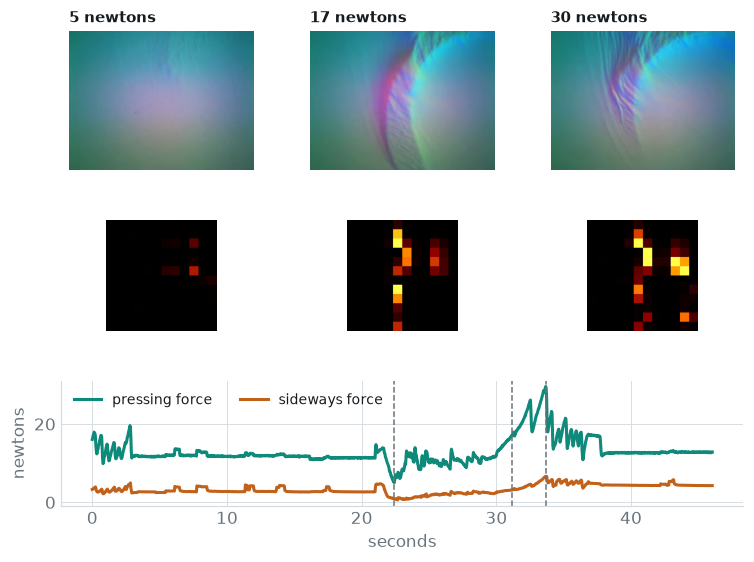

1382 readings over 46 s = 30 per second;  gel image (240, 320, 3),  pressure map (192, 192, 3)


In [3]:
p = data.tactile_press(); t, ft, idx = p["t"], p["ft"], p["idx"]; fig = plt.figure(figsize=(8, 5.6)); gs = fig.add_gridspec(3, 3, height_ratios=[1, 0.8, 0.9], hspace=0.4)
for k in range(3):
    a = fig.add_subplot(gs[0, k]); a.imshow(p["tac"][k]); a.set_title(f"{-ft[idx[k], 2]:.0f} newtons", fontsize=10); style.bare(a); b = fig.add_subplot(gs[1, k]); b.imshow(p["pm"][k]); style.bare(b)
c = fig.add_subplot(gs[2, :]); c.plot(t, -ft[:, 2], label="pressing force"); c.plot(t, np.hypot(ft[:, 0], ft[:, 1]), label="sideways force")
for i in idx: c.axvline(t[i], color=style.MUTED, ls="--", lw=1)
c.set_xlabel("seconds"); c.set_ylabel("newtons"); c.legend(ncol=2, fontsize=9); plt.show()
print(f"{len(t)} readings over {t[-1]:.0f} s = {len(t) / t[-1]:.0f} per second;  gel image {p['tac'][0].shape},  pressure map {p['pm'][0].shape}")

The gel camera shows the shape pressing into the finger. The pressure array shows where contact is.
The force sensor gives one clean number for how hard, and nothing about where.

## Sound: from waveform to spectrogram

A waveform is air pressure over time: 16,000 numbers a second. A spectrogram shows the same sound as
pitch against time. It is built by cutting the signal into short overlapping windows and taking the
Fourier transform of each.

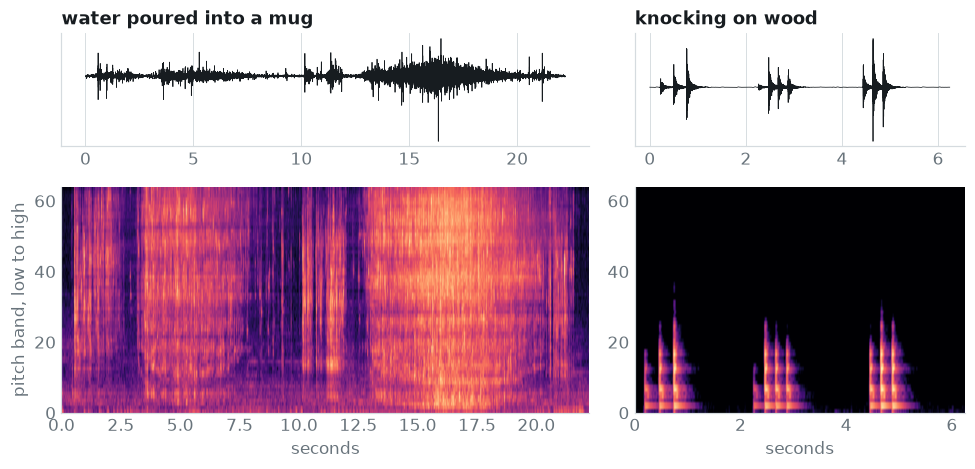

In [4]:
def spectrogram(x, n_fft=1024, hop=160):
    window = np.hanning(n_fft); frames = np.stack([x[i:i + n_fft] * window for i in range(0, len(x) - n_fft, hop)])
    return np.abs(np.fft.rfft(frames, axis=1)) ** 2                                   # (time, frequency) power

def mel_filterbank(n_fft, sr, n_mels=64, fmin=50, fmax=8000):
    to_mel = lambda f: 2595 * np.log10(1 + f / 700); to_hz = lambda m: 700 * (10 ** (m / 2595) - 1)
    edges = to_hz(np.linspace(to_mel(fmin), to_mel(fmax), n_mels + 2)); freqs = np.fft.rfftfreq(n_fft, 1 / sr); W = np.zeros((n_mels, len(freqs)))
    for i in range(n_mels): lo, mid, hi = edges[i:i + 3]; W[i] = np.clip(np.minimum((freqs - lo) / (mid - lo), (hi - freqs) / (hi - mid)), 0, None)
    return W

def log_mel(x, sr): return 10 * np.log10(spectrogram(x) @ mel_filterbank(1024, sr).T + 1e-10)      # (time, 64 bands), in decibels

fig, ax = plt.subplots(2, 2, figsize=(9, 4.4), gridspec_kw=dict(height_ratios=[0.5, 1], width_ratios=[1.6, 1]))
for j, name in enumerate(("pour", "knock")):
    x, sr = data.audio(name); M = log_mel(x, sr); ax[0, j].plot(np.arange(len(x))[::8] / sr, x[::8], color=style.INK, lw=0.5); ax[0, j].set_title({"pour": "water poured into a mug", "knock": "knocking on wood"}[name]); ax[0, j].set_yticks([])
    ax[1, j].imshow(M.T, origin="lower", aspect="auto", cmap="magma", vmin=M.max() - 60, vmax=M.max(), extent=(0, len(x) / sr, 0, 64)); ax[1, j].set_xlabel("seconds"); ax[1, j].grid(False)
ax[1, 0].set_ylabel("pitch band, low to high"); plt.tight_layout(); plt.show()

A continuous flow and a sharp contact look nothing alike. Each knock is a column of bands that rings and fades.

## The window length is a trade

A long window resolves pitch finely and blurs timing. A short one does the reverse.

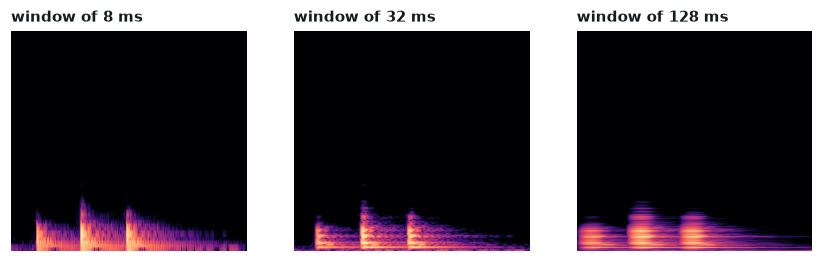

In [5]:
x, sr = data.audio("knock"); peak = np.argmax(np.convolve(np.abs(x), np.ones(800) / 800, "same")); seg = x[max(0, peak - 5600): peak + 12000]; fig, ax = plt.subplots(1, 3, figsize=(9.4, 2.6))
for a, n in zip(ax, (128, 512, 2048)):
    P = 10 * np.log10(spectrogram(seg, n_fft=n, hop=64) + 1e-10); a.imshow(P.T[: n // 2], origin="lower", aspect="auto", cmap="magma", vmin=P.max() - 70, vmax=P.max()); a.set_title(f"window of {n / sr * 1000:.0f} ms", fontsize=10); style.bare(a)
plt.show()

## From sound to tokens

A transformer takes tokens. One second of sound becomes a 64 x 96 spectrogram, which is cut into
16 x 16 patches exactly as a photo would be.

one second: 17,600 numbers  ->  spectrogram (64, 96)  ->  24 patches of 256 numbers each


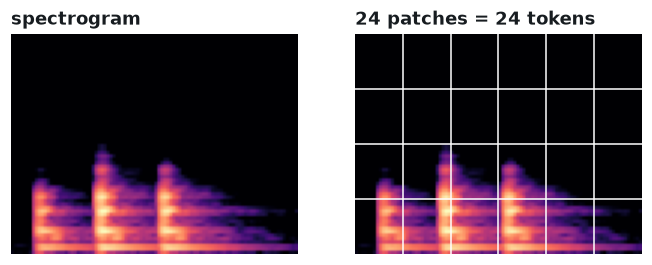

In [6]:
M = log_mel(seg, sr)[:96].T; patches = M.reshape(4, 16, 6, 16).transpose(0, 2, 1, 3).reshape(24, 256)
print(f"one second: {len(seg):,} numbers  ->  spectrogram {M.shape}  ->  {patches.shape[0]} patches of {patches.shape[1]} numbers each")
fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.6)); ax[0].imshow(M, origin="lower", aspect="auto", cmap="magma", vmin=M.max() - 60); ax[0].set_title("spectrogram"); ax[1].imshow(M, origin="lower", aspect="auto", cmap="magma", vmin=M.max() - 60); ax[1].set_title("24 patches = 24 tokens")
for k in range(1, 6): ax[1].axvline(k * 16 - 0.5, color="white", lw=1)
for k in range(1, 4): ax[1].axhline(k * 16 - 0.5, color="white", lw=1)
for a in ax: style.bare(a)
plt.show()

## Why a fast signal needs a window

A policy runs 10 to 50 times a second. If it reads only the latest force value at each step, what does
it miss? Add a brief spike to the force trace, of the kind an impact makes, and sample it at 10 per second.

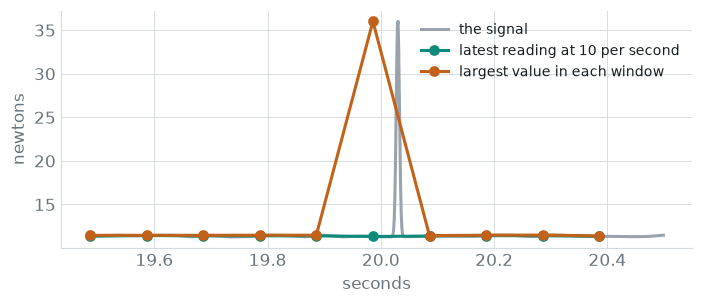

the spike adds 25 N; the latest-reading samples see at most 0.0 N of it, the windowed summary 24.5 N


In [7]:
fz = -ft[:, 2]; rate = len(t) / t[-1]; fine_t = np.linspace(0, t[-1], len(t) * 30); fine = np.interp(fine_t, t, fz); spike_at = 20.03
fine += 25 * np.exp(-((fine_t - spike_at) / 0.004) ** 2)                               # a 10 ms impact
step = int(len(fine_t) / (t[-1] * 10)); latest = fine[::step]; window_max = np.array([fine[i:i + step].max() for i in range(0, len(fine), step)])
sl = slice(int(19.5 * 10), int(20.5 * 10)); plt.figure(figsize=(7.4, 2.8)); mask = (fine_t > 19.5) & (fine_t < 20.5); plt.plot(fine_t[mask], fine[mask], color=style.GREY, label="the signal")
plt.plot(fine_t[::step][sl], latest[sl], "o-", label="latest reading at 10 per second"); plt.plot(fine_t[::step][sl], window_max[:len(latest)][sl], "o-", label="largest value in each window"); plt.xlabel("seconds"); plt.ylabel("newtons"); plt.legend(fontsize=9); plt.show()
print(f"the spike adds 25 N; the latest-reading samples see at most {latest[sl].max() - np.median(latest[sl]):.1f} N of it, the windowed summary {window_max[sl].max() - np.median(window_max[sl]):.1f} N")

## Things to try

- Compute a spectrogram of the force trace itself. Is there anything above a few cycles per second?
- Add white noise to the knock at increasing levels. When do the knocks disappear from the spectrogram?
- Detect each knock automatically from the spectrogram's energy, and count them.